<a href="https://colab.research.google.com/github/lkot0004/MMA3001-Linda/blob/main/Missing_Sensor_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#this so that anyone can run the notebook as long as they have the dataset
#use the MMA3001 environmental *ZIP* file or upload
#the origional enviro dataset when prompted by the next cell
from pathlib import path
print("this is a portable notebook: the dataset will be searched locally or requested by upload")

Mounted at /content/drive


#Environmental sensor data audit
This section is to investigate the structure and quality of the environmental sensor data set. We will ectract the temperature measurements, identify the duplicate observations, examine smapling intervals and choose a suitable time series data for the numerical reconstruction experiments.

In [ ]:
import pandas as pd #org and clean sensor observations
import numpy as np #numerical calc
import json #decode the stored sensor measurements
import zipfile #read compressed data
from pathlib import Path #find google drive files
import matplotlib.pyplot as plt #plot graphs

print("libraries all imported")

libraries all imported


In [ ]:
#Find the original environmental dataset archive without private Drive access.
#Permitted sources: a local `data/` folder, the Colab session, or a user upload.
from pathlib import Path
import zipfile

candidate_folders = [
    Path.cwd() / "data",
    Path.cwd(),
    Path("/content/MMA3001-Linda/data"),
    Path("/content/MMA3001-Linda"),
    Path("/content/data"),
    Path("/content"),
]

env_zip = None
for folder in candidate_folders:
    if folder.is_dir():
        matches = sorted(folder.glob("*EnvSensor*.zip"))
        if matches:
            env_zip = matches[0]
            break

if env_zip is None:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Environmental ZIP missing. Download the original '*EnvSensor*.zip' "
            "from the MMA3001 dataset materials, place it in a local 'data/' "
            "folder beside the notebook, and rerun this cell."
        ) from exc
    print("Upload the course-provided *EnvSensor*.zip environmental archive.")
    uploaded = files.upload()
    candidates = [Path.cwd() / filename for filename in uploaded
                  if filename.lower().endswith(".zip") and "envsensor" in filename.lower()]
    if not candidates:
        raise FileNotFoundError(
            "No environmental ZIP was uploaded. Rerun and select *EnvSensor*.zip."
        )
    env_zip = sorted(candidates)[0]

data_folder = env_zip.parent
with zipfile.ZipFile(env_zip) as archive:
    csv_names = [name for name in archive.namelist() if name.lower().endswith(".csv")]
    if not csv_names:
        raise ValueError(f"Dataset ZIP does not contain a CSV file: {env_zip}")
    print("Environmental dataset:", env_zip.resolve())
    print("ZIP contents:", archive.namelist())

Upload the course-provided *EnvSensor*.zip environmental archive.


In [ ]:
#starting with 20000 of the 180000 records for initial inspections
#opening zip
with zipfile.ZipFile(env_zip) as archive:

  #find CSV in zip
   csv_name = next(
        name for name in archive.namelist()
        if name.lower().endswith(".csv"))

  #read the first 20k records
   with archive.open(csv_name) as file:
        env_data = pd.read_csv(
            file,
            nrows=20000,
            dtype={"sensorid": str})

print("Dataset dimensions:", env_data.shape) #returns no. of rowns and columns

#look at the first 5 records
display(env_data.head())





In [ ]:
#extracting the temp measurements
#step 1 data processing
#extract the temp values and their associated timestamps

#func ot extract temp obs

def extract_temperature(data):
    """
    Extract temperature measurements and Unix timestamps
    from environmental sensor JSON records.

    Parameters
    ----------
    data : pandas.DataFrame
        Environmental sensor records.

    Returns
    -------
    pandas.DataFrame
        Sensor ID, timestamp and temperature.
    """
    records = []

    for row in data.itertuples(index=False):

        if pd.isna(row.jsondata):
            continue

        try:
            measurements = json.loads(row.jsondata)
        except (json.JSONDecodeError, TypeError):
            continue

        for measurement in measurements:

            variable = measurement.get("variable", {})

            if variable.get("name") == "Temperature":

                for reading in measurement.get("values", []):

                    records.append({
                        "sensorid": row.sensorid,
                        "timestamp": reading.get("time"),
                        "temperature": reading.get("value")
                    })

    return pd.DataFrame(records)


# Extract temperature values again
temperature_data = extract_temperature(env_data)

# Convert Unix timestamps to datetime
temperature_data["timestamp"] = pd.to_datetime(
    temperature_data["timestamp"],
    unit="s",
    utc=True,
    errors="coerce"
)

# Ensure temperature values are numeric
temperature_data["temperature"] = pd.to_numeric(
    temperature_data["temperature"],
    errors="coerce"
)

display(temperature_data.head())

,sensorid,timestamp,temperature
0,6012002000241,2023-12-11 05:52:45+00:00,23.8
1,6012002000241,2023-12-11 05:52:45+00:00,23.8
2,6012002000326,2023-12-11 05:00:57+00:00,23.8
3,6012002000777,2023-05-05 22:42:45+00:00,18.8
4,6012002000869,2024-02-29 06:04:56+00:00,24.3


In [ ]:
#check data quality
#convert the timestamp and temp into suitable types
temperature_data["timestamp"] = pd.to_datetime(
    temperature_data["timestamp"],
    unit="s",
    utc=True,
    errors="coerce"
)

temperature_data["temperature"] = pd.to_numeric(
    temperature_data["temperature"],
    errors="coerce"
)

#check data quality
print("missing values:")
print(temperature_data.isna().sum())

print("\nNumber of sensors:")
print(temperature_data["sensorid"].nunique())

print("\nDuplicate sensor-timestamp pairs:")
print(
    temperature_data.duplicated(
        subset=["sensorid","timestamp"]
    ).sum()
)

print("\nData range:")
print(temperature_data["timestamp"].agg(["min","max"]))


missing values:
sensorid       0
timestamp      0
temperature    0
dtype: int64

Number of sensors:
4

Duplicate sensor-timestamp pairs:
15104

Data range:
min   2023-05-05 22:42:45+00:00
max   2024-04-08 05:35:13+00:00
Name: timestamp, dtype: datetime64[ns, UTC]


In [ ]:
#inspecting teh available sensors
#number of distinct timestamps for each sensor
sensor_summary = (
    temperature_data
    .groupby("sensorid")
    .agg(
        records = ("temperature","size"),
        unique_times=("timestamp","nunique"),
        min_temp=("temperature","min"),
        max_temp=("temperature","max"),
    )
    .sort_values("unique_times",ascending=False)
)

display(sensor_summary)

,records,unique_times,min_temp,max_temp
sensorid,,,,
6012002000869,4999,4893,20.3,28.5
6012002000241,5002,1,23.8,23.8
6012002000326,4999,1,23.8,23.8
6012002000777,5000,1,18.8,18.8


sensor 6012002000869 is the best candidate for this sample.

In [ ]:
#investigating the duplicate measurements
#we are picking the sensor with the most unique timestamps
selected_sensor = "6012002000869"

sensor_data = temperature_data[
    temperature_data["sensorid"].astype(str) == selected_sensor
].copy()

#have a look at the repeated timestamps
duplicate_check = (
    sensor_data.groupby("timestamp")
    .agg(
        records = ("temperature","size"),
        unique_sensors=("sensorid","nunique"),
        min_temp=("temperature","min"),
        max_temp=("temperature","max"),
)
)

print("total records:", len(sensor_data))
print("unique timestamps:", sensor_data["timestamp"].nunique())

print("Timestamps occuring more than once:", (duplicate_check["records"]>1).sum())


display(duplicate_check[duplicate_check["records"] > 1].head(10))
#

total records: 4999
unique timestamps: 4893
Timestamps occuring more than once: 106


,records,unique_sensors,min_temp,max_temp
timestamp,,,,
2024-02-29 21:44:57+00:00,2,1,23.5,23.5
2024-03-04 16:24:59+00:00,2,1,22.0,22.0
2024-03-04 16:34:57+00:00,2,1,22.0,22.0
2024-03-04 17:04:59+00:00,2,1,21.8,21.8
2024-03-04 17:25:00+00:00,2,1,21.8,21.8
2024-03-04 17:44:59+00:00,2,1,21.8,21.8
2024-03-04 18:14:57+00:00,2,1,21.5,21.5
2024-03-04 18:24:57+00:00,2,1,21.5,21.5
2024-03-04 18:54:58+00:00,2,1,21.5,21.5


In [ ]:
#make a clean temp time series
#identify the timestamps without conflicting readings

valid_times = duplicate_check[
    duplicate_check["min_temp"] == duplicate_check["max_temp"]
].index

#keep only the consistent observations
clean_data = sensor_data[
    sensor_data["timestamp"].isin(valid_times)
].copy()

#remove the repeated identical readings
clean_data = clean_data.drop_duplicates(
    subset=["timestamp"]
)

#sort them into chronological order
clean_data = clean_data.sort_values("timestamp")

print("clean observations:",len(clean_data))
print("Start:", clean_data["timestamp"].min())
print("End:", clean_data["timestamp"].max())

display(clean_data.head())

clean observations: 4893
Start: 2024-02-29 06:04:56+00:00
End: 2024-04-08 05:35:13+00:00


,sensorid,timestamp,temperature
4,6012002000869,2024-02-29 06:04:56+00:00,24.3
8,6012002000869,2024-02-29 06:14:57+00:00,24.0
12,6012002000869,2024-02-29 06:34:57+00:00,23.8
16,6012002000869,2024-02-29 06:44:57+00:00,23.8
20,6012002000869,2024-02-29 06:54:57+00:00,23.8


In [ ]:
#we then investigate the smapling intervals
#calculate the time in between teh consecutive observations

clean_data["time_difference"] = (
    clean_data["timestamp"]
    .diff()
)

#convert the time diff to minutes
clean_data["interval_minutes"] = (
    clean_data["time_difference"]
    .dt.total_seconds()
    .div(60)
)

print("sampling interval stats (minutes):")
print(clean_data["interval_minutes"].describe())

print("\nMost common intervals:")
print(
    clean_data["interval_minutes"]
    .round(2)
    .value_counts()
    .head(10)

)

sampling interval stats (minutes):
count    4892.000000
mean       11.473893
std         3.545374
min         9.800000
25%        10.000000
50%        10.000000
75%        10.016667
max        20.200000
Name: interval_minutes, dtype: float64

Most common intervals:
interval_minutes
10.00    2922
10.02     524
9.98      499
20.00     463
9.97      102
20.02     102
10.03      98
19.98      98
19.97      27
20.03      26
Name: count, dtype: int64


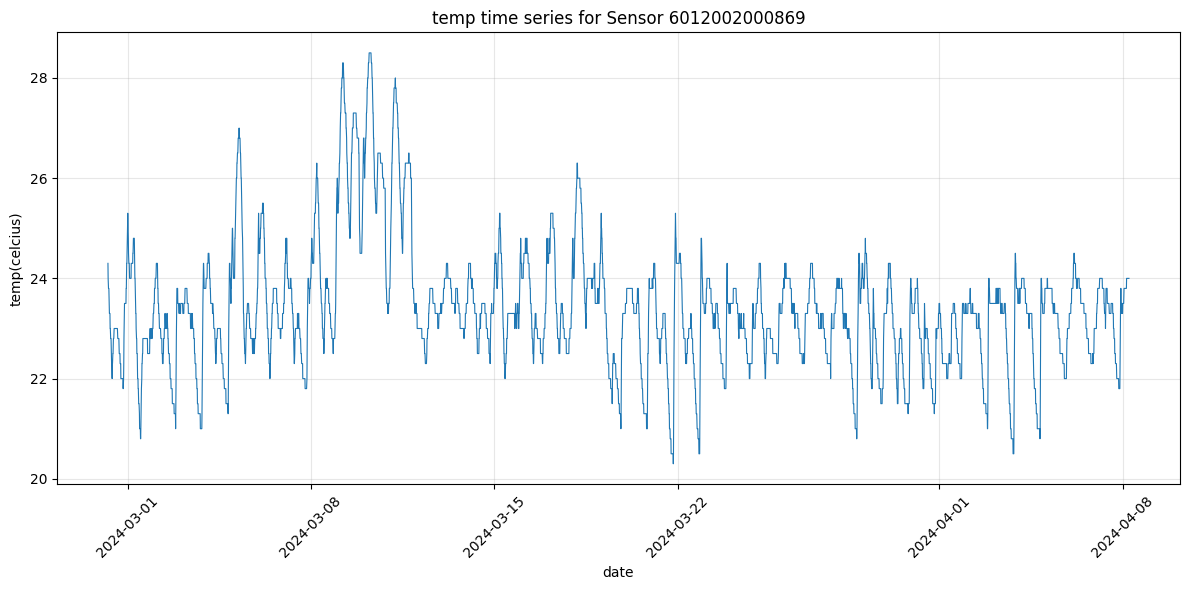

In [ ]:
#generating the graph
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

# Plot
plt.plot(
    clean_data["timestamp"],
    clean_data["temperature"],
    linewidth=0.8
)

plt.xlabel("date")
plt.ylabel("temp(celcius)")
plt.title("temp time series for Sensor 6012002000869")

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
#


In [ ]:
#convert the measurements into a regular time series
#keep omly timestamp and temperature
experiment_data = clean_data[
    ["timestamp","temperature"]
].copy()

#use the timestamps as the dataframe index
experiment_data = experiment_data.set_index("timestamp").sort_index()

display(experiment_data.head())

#group the measurements into regular 10minute intervals
regular_data = experiment_data.resample("10min").mean()
print(
    "slots with the measurements:",
    regular_data["temperature"].isna().sum()
)

display(regular_data.head(10))

,temperature
timestamp,
2024-02-29 06:04:56+00:00,24.3
2024-02-29 06:14:57+00:00,24.0
2024-02-29 06:34:57+00:00,23.8
2024-02-29 06:44:57+00:00,23.8
2024-02-29 06:54:57+00:00,23.8


slots with the measurements: 721


,temperature
timestamp,
2024-02-29 06:00:00+00:00,24.3
2024-02-29 06:10:00+00:00,24.0
2024-02-29 06:20:00+00:00,NaN
2024-02-29 06:30:00+00:00,23.8
2024-02-29 06:40:00+00:00,23.8
2024-02-29 06:50:00+00:00,23.8
2024-02-29 07:00:00+00:00,NaN
2024-02-29 07:10:00+00:00,23.5
2024-02-29 07:20:00+00:00,23.3


In [ ]:
#Identify whether each time slot has an observation
regular_data["observed"] = (
    regular_data["temperature"].notna()
)

#Assign a group number whenever the status change
regular_data["group"] = (
    regular_data["observed"
    ].ne(regular_data["observed"].shift())
    .cumsum()
)

#then summarise continuos runs
run_summary = (
    regular_data
    .groupby(["group","observed"])
    .size()
    .reset_index(name="length")
)

#show the longest observed runs we have
longest_runs = (
    run_summary[run_summary["observed"]]
    .sort_values("length",ascending=False)
)

display(longest_runs.head(10)
)

,group,observed,length
312,313,True,66
390,391,True,65
384,385,True,55
1426,1427,True,13
1406,1407,True,13
1440,1441,True,13
1428,1429,True,13
1368,1369,True,13
1362,1363,True,13
1396,1397,True,13


In [ ]:
#we check if we have enough continuous data
print("longest observed run:")
print(longest_runs["length"].max(), "measurements")

print("\nNumber of observed runs:")
print(len(longest_runs))

print("\nRuns containing atleast 30 measurements:")
print((longest_runs["length"]>= 30).sum())

print("\nRuns containing atleast 50 measurements:")
print((longest_runs["length"]>= 50).sum())

print("\nRuns containing atleast 100 measurements:")
print((longest_runs["length"]>= 100).sum())


longest observed run:
66 measurements

Number of observed runs:
722

Runs containing atleast 30 measurements:
3

Runs containing atleast 50 measurements:
3

Runs containing atleast 100 measurements:
0


selected measurements: 66
start: 2024-03-04 16:20:00+00:00
end: 2024-03-05 03:10:00+00:00


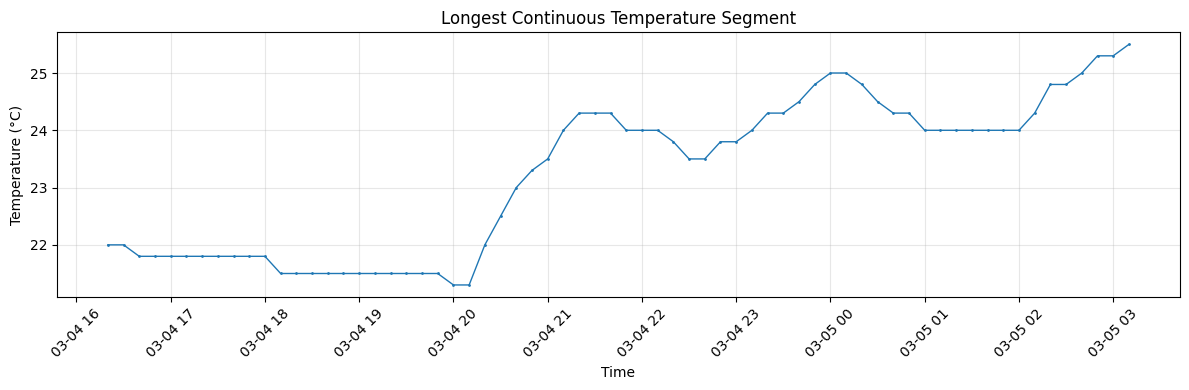

In [ ]:
#visualise the longest run
#find the longest observed group
longest_group = longest_runs.iloc[0]["group"]

#extract its temp measurements
test_series = regular_data.loc[
    regular_data["group"] == longest_group,
    ["temperature"]
].copy()

print("selected measurements:", len(test_series))
print("start:",test_series.index.min())
print("end:",test_series.index.max())

#plotting the obs temps
plt.figure(figsize=(12,4))

plt.plot(
    test_series.index,
    test_series["temperature"],
    marker=".",
    markersize=2,
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Longest Continuous Temperature Segment")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#  CONTROLLED MISSING DATA RECONSTR EXPT

EXPERIMENT 1; hide 5 consecutive temp measurements then use the 3 methods to reconstruct them // the plan is to then compare the predictions against the origional values that we withheld

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from time import perf_counter

#copy the continuos temp series we chose
experiment = test_series[["temperature"]].copy()

#make sure its in chronological series
experiment = experiment.sort_index()

#double check that the segment is suitable
assert len(experiment) >= 30, "insufficient obervation number"
assert experiment.index.is_unique, "duplicate timestamps found"
assert experiment.index.is_monotonic_increasing
assert experiment["temperature"].notna().all()

print("Measurements:", len(experiment))
print("First measurement:", experiment.index.min())
print("Last measurement:", experiment.index.max())
print("Temperature range:",
      experiment["temperature"].min(),
      "to",
      experiment["temperature"].max(), "°C")

Measurements: 66
First measurement: 2024-03-04 16:20:00+00:00
Last measurement: 2024-03-05 03:10:00+00:00
Temperature range: 21.3 to 25.5 °C


In [ ]:
#removing the 5 temperature measurements near the middle of the 66 pt sequence
#no. of consecutive readings to hide
gap_length = 5

#choosing a central starting position
gap_start = len(experiment) // 2 - gap_length // 2

#make a copy of the measured temperatures
origional = experiment["temperature"].copy()

#make an artificially incomplete data set
incomplete = origional.copy()

#find the positions to hide within the sequence
hidden_positions= np.arange(
    gap_start,
    gap_start + gap_length
)

#we find and store the true vals using the origional seq
#this is so we can validate them later

actual_hidden = origional.iloc[hidden_positions].to_numpy()

#now hide the values
incomplete.iloc[hidden_positions] = np.nan

print("the hidden measurements are:")
display(pd.DataFrame({
    "timestamp": origional.index[hidden_positions],
    "actual_temperature": actual_hidden,
}))

print("the number of missing values is:",
      incomplete.isna().sum())


the hidden measurements are:


,timestamp,actual_temperature
0,2024-03-04 21:30:00+00:00,24.3
1,2024-03-04 21:40:00+00:00,24.3
2,2024-03-04 21:50:00+00:00,24.0
3,2024-03-04 22:00:00+00:00,24.0
4,2024-03-04 22:10:00+00:00,24.0


the number of missing values is: 5


In [ ]:
#making numerical time coordinates
#convert timestamps to minutes passed
time_minutes = (
    experiment.index - experiment.index[0]
).total_seconds().to_numpy()/60

#identify measured and hidden values
known_mask = incomplete.notna().to_numpy()
missing_mask = incomplete.isna().to_numpy()

#have a look at the available obsv
known_times = time_minutes[known_mask]
known_temperatures = incomplete[known_mask].to_numpy()

# Times requiring reconstruction
missing_times = time_minutes[missing_mask]

print("Known observations:", len(known_times))
print("Hidden observations:", len(missing_times))

Known observations: 61
Hidden observations: 5


# Reconstruction methods

In [ ]:
#method 1; forward fill
start = perf_counter()

forward_result = incomplete.ffill()
forward_predictions = forward_result.iloc[
    hidden_positions
].to_numpy()

forward_time = perf_counter() - start

#method 2; Linear interpolation
start = perf_counter()

linear_predictions = np.interp(
    missing_times,
    known_times,
    known_temperatures
)

linear_time = perf_counter() - start

#method 3; Linear interpolation
start = perf_counter()

pchip_model = PchipInterpolator(
    known_times,
    known_temperatures,
    extrapolate=False
)

pchip_predictions = pchip_model(missing_times)

pchip_time = perf_counter() - start

print("All reconstruction methods done.")


All reconstruction methods done.


# Using a function to calculate the errors

In [ ]:
def calculate_errors(actual, predicted):
    """Calculate MAE and RMSE in temperature units."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    if actual.shape != predicted.shape:
        raise ValueError("Prediction shape mismatch")

    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Non-finite temperature values")

    errors = actual - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))

    return mae, rmse

# Collect predictions and timing measurements
predictions = {
    "Forward fill": (forward_predictions, forward_time),
    "Linear": (linear_predictions, linear_time),
    "PCHIP": (pchip_predictions, pchip_time)
}

results = []

for method, (estimated, runtime) in predictions.items():

    mae, rmse = calculate_errors(
        actual_hidden,
        estimated
    )

    results.append({
        "Method": method,
        "MAE (°C)": mae,
        "RMSE (°C)": rmse,
        "Runtime (ms)": runtime * 1000
    })

results_df = pd.DataFrame(results)

display(results_df.round(5))



,Method,MAE (°C),RMSE (°C),Runtime (ms)
0,Forward fill,0.18000,0.23238,4.66941
1,Linear,0.09000,0.10193,0.16658
2,PCHIP,0.07274,0.08742,2.41645


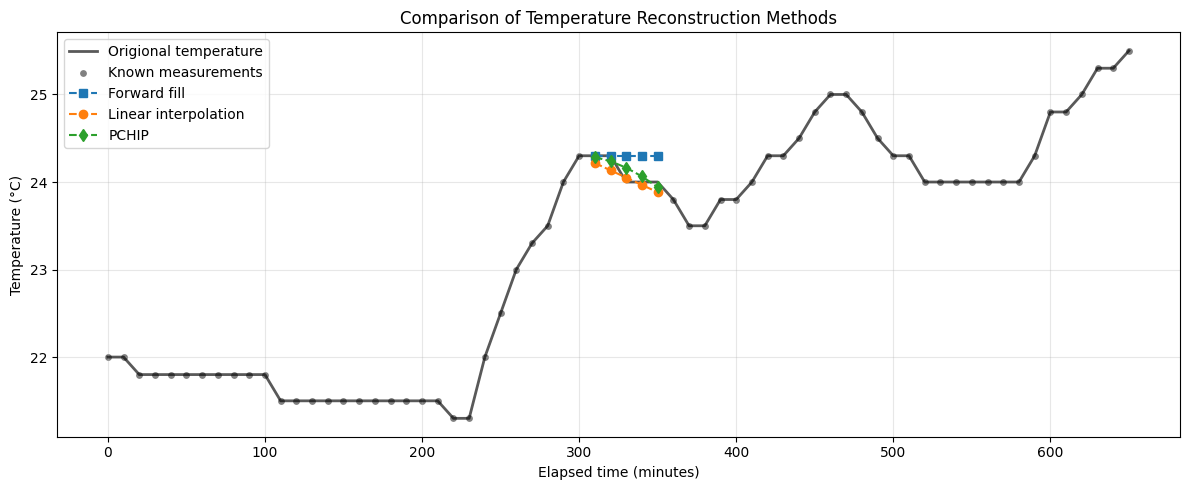

In [ ]:
#plot the reconstruction to visualise it
plt.figure(figsize=(12, 5))

# True temperature measurements
plt.plot(
    time_minutes,
    origional.to_numpy(),
    label="Origional temperature",
    color="black",
    linewidth=2,
    alpha=0.65
)

# Available observations
plt.scatter(
    known_times,
    known_temperatures,
    label="Known measurements",
    color="grey",
    s=15
)

# Predictions at the hidden positions
plt.plot(
    missing_times,
    forward_predictions,
    "s--",
    label="Forward fill"
)

plt.plot(
    missing_times,
    linear_predictions,
    "o--",
    label="Linear interpolation"
)

plt.plot(
    missing_times,
    pchip_predictions,
    "d--",
    label="PCHIP"
)

plt.xlabel("Elapsed time (minutes)")
plt.ylabel("Temperature (°C)")
plt.title("Comparison of Temperature Reconstruction Methods")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()




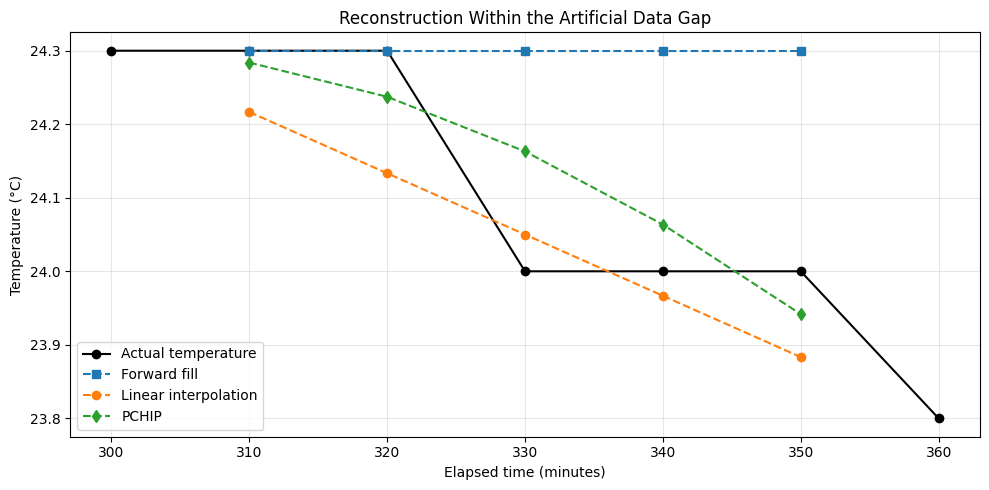

In [ ]:
#gonna zoom in to see it better
plt.figure(figsize=(10, 5))

# Include one measured point on each side of the gap
left = hidden_positions[0] - 1
right = hidden_positions[-1] + 1

plot_positions = np.arange(left, right + 1)

plt.plot(
    time_minutes[plot_positions],
    origional.iloc[plot_positions],
    "ko-",
    label="Actual temperature"
)

plt.plot(
    missing_times,
    forward_predictions,
    "s--",
    label="Forward fill"
)

plt.plot(
    missing_times,
    linear_predictions,
    "o--",
    label="Linear interpolation"
)

plt.plot(
    missing_times,
    pchip_predictions,
    "d--",
    label="PCHIP"
)

plt.xlabel("Elapsed time (minutes)")
plt.ylabel("Temperature (°C)")
plt.title("Reconstruction Within the Artificial Data Gap")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


In [ ]:
#having a look at how much data we actually resampled
print("Original clean measurements:", len(clean_data))
print("Resampled time slots:", len(regular_data))

print(
    "Observed resampled slots:",
    regular_data["temperature"].notna().sum()
)

print(
    "Missing resampled slots:",
    regular_data["temperature"].isna().sum()
)

print("Resampled period:")
print(regular_data.index.min())
print(regular_data.index.max())


Original clean measurements: 4893
Resampled time slots: 5614
Observed resampled slots: 4893
Missing resampled slots: 721
Resampled period:
2024-02-29 06:00:00+00:00
2024-04-08 05:30:00+00:00


Now, going to repeat the experiment but alter the gap lengths

In [ ]:
def reconstruct_gap(series, gap_start, gap_length):
    """
    Comparing the three methods for reconstructing a missing block.

    Parameters;
    series : pandas.Series
        Original temperature measurements with timestamps.
    gap_start : int
        Index position where the missing block begins.
    gap_length : int
        Number of consecutive measurements to hide.

    Returns;
    pandas.DataFrame
        Reconstruction errors for each method.
    """

    # first we preserve the original measurements
    original = series.copy()
    incomplete = original.copy()

     # then identify the values to hide
    positions = np.arange(
        gap_start,
        gap_start + gap_length
    )

    actual = original.iloc[positions].to_numpy()

      # then simulate missing measurements
    incomplete.iloc[positions] = np.nan

     #convert the timestamps into elapsed minutes
    t = (
        original.index - original.index[0]
    ).total_seconds().to_numpy() / 60

    #separete the available and missing observations
    known= incomplete.notna().to_numpy()
    hidden = ~known

    x_known = t[known]
    y_known = incomplete.to_numpy()[known]
    x_hidden = t[hidden]

    #we can then reconstruct the missing values
    forward = incomplete.ffill().iloc[positions].to_numpy()
    linear = np.interp(
        x_hidden,
        x_known,
        y_known
    )
    pchip = PchipInterpolator(
        x_known,
        y_known,
        extrapolate=False
    )(x_hidden)

    #evaluate the three methods
    results = []

    for method, predicted in {
        "Forward fill": forward,
        "Linear": linear,
        "PCHIP": pchip
    }.items():

        mae, rmse = calculate_errors(
            actual,
            predicted
        )
        results.append({
            "method": method,
            "gap_start": gap_start,
            "gap_length": gap_length,
            "mae": mae,
            "rmse": rmse
        })

    return pd.DataFrame(results)

In [ ]:
#gonna test the function
#temp serues from our chosen continuos segment
series = test_series["temperature"]

# Repeat the original five-measurement experiment
pilot_check = reconstruct_gap(
    series,
    gap_start=len(series) // 2 - 2,
    gap_length=5
)

display(pilot_check.round(5))

,method,gap_start,gap_length,mae,rmse
0,Forward fill,31,5,0.18000,0.23238
1,Linear,31,5,0.09000,0.10193
2,PCHIP,31,5,0.07274,0.08742


We're gonna have a look at 5 different gap lengths. 1 measurement = 10mins all the way to 8 measurements = 80mins

In [ ]:
#gap lengths we want to have a look at
gap_lengths = [1, 2, 3, 5, 8]

#we then store the results from each expt
all_results = []

for gap_length in gap_lengths:

    #choose 5 starting positions
    starts = np.linspace(
        5,
        len(series) - gap_length - 5,
        5,
        dtype=int
    )

    for start in starts:
      #recosntructing the missing block
      result = reconstruct_gap(
          series,
          int(start),
          gap_length
      )
      #store the results
      all_results.append(result)

#we then combine the results into 1 table
validation_results = pd.concat(
    all_results,
    ignore_index=True
)

print("Number of method evaluations:", len(validation_results))

display(validation_results.head(10))


Number of method evaluations: 75


,method,gap_start,gap_length,mae,rmse
0,Forward fill,5,1,0.00,0.00
1,Linear,5,1,0.00,0.00
2,PCHIP,5,1,0.00,0.00
3,Forward fill,18,1,0.00,0.00
4,Linear,18,1,0.00,0.00
5,PCHIP,18,1,0.00,0.00
6,Forward fill,32,1,0.00,0.00
7,Linear,32,1,0.15,0.15
8,PCHIP,32,1,0.15,0.15
9,Forward fill,46,1,0.20,0.20


In [ ]:
#calculating the mean reconstruction error

summary = (
    validation_results
    .groupby(["gap_length", "method"])
    .agg(
        mean_MAE=("mae","mean"),
        mean_RMSE=("rmse","mean"),
        std_MAE=("mae","std"),
        #std_RMSE=("rmse","std") - why dont we have this
    )
    .reset_index()
)

display(summary.round(4))

,gap_length,method,mean_MAE,mean_RMSE,std_MAE
0,1,Forward fill,0.1400,0.1400,0.2191
1,1,Linear,0.1000,0.1000,0.1061
2,1,PCHIP,0.0893,0.0893,0.1025
3,2,Forward fill,0.2200,0.2457,0.2465
4,2,Linear,0.0800,0.0882,0.0758
5,2,PCHIP,0.0781,0.0810,0.0918
6,3,Forward fill,0.1867,0.2353,0.2168
7,3,Linear,0.0767,0.0826,0.0742
8,3,PCHIP,0.0613,0.0720,0.0574
9,5,Forward fill,0.1640,0.2237,0.1752


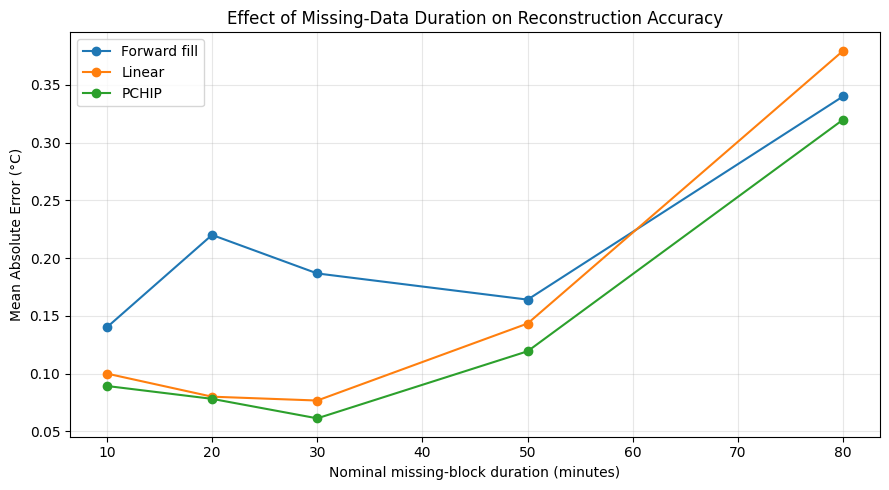

In [ ]:
#a graph to see how error changes with gap length
plt.figure(figsize=(9, 5))

for method, group in summary.groupby("method"):

    plt.plot(
        group["gap_length"] * 10,
        group["mean_MAE"],
        marker="o",
        label=method
    )

plt.xlabel("Nominal missing-block duration (minutes)")
plt.ylabel("Mean Absolute Error (°C)")
plt.title("Effect of Missing-Data Duration on Reconstruction Accuracy")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#We will now perform independent validation and test the methods on temperature segments that were not used for out pilot and sensitivity experiments

In [ ]:
#we find the 3 longest observed runs from ealier
top_runs = longest_runs.head(3)

#display the lengths
display(top_runs)

#estract each segment
validation_segments = []

for group_id in top_runs["group"].iloc[1:]:

    segment = regular_data.loc[
        regular_data["group"] == group_id,
        "temperature"
    ].copy()

    validation_segments.append(segment)

#show info about the independent segments
for i, segment in enumerate(validation_segments, start=1):
    print(f"Validation segment {i}:")
    print("Observations:", len(segment))
    print(f"Start:", segment.index.min())
    print(f"End:", segment.index.max())
    print("Temperature range:",
          segment.min(), "to", segment.max())
    print()
#this will exclude our origional longest segment that we used to develop the methods
#and assess their performance

,group,observed,length
312,313,True,66
390,391,True,65
384,385,True,55


Validation segment 1:
Observations: 65
Start: 2024-03-06 13:00:00+00:00
End: 2024-03-06 23:40:00+00:00
Temperature range: 22.8 to 23.8

Validation segment 2:
Observations: 55
Start: 2024-03-06 02:20:00+00:00
End: 2024-03-06 11:20:00+00:00
Temperature range: 22.0 to 25.5



# INDEPENDENT VALIDATION ON UNUSED TEMP SEGMENTS

Running the independient validations now using the unused segments adn we will not be changing the methods basaed on these results. This preserves their roles as the independent evaluation data.




In [ ]:
#gap lengths used during the dev stage
gap_lengths = [1,2,3,5,8]
independent_results= []

for segment_id, segment in enumerate(validation_segments, start=1):

    #check the segment has adequate readings
    assert len(segment) >= max(gap_lengths) +12
    assert segment.notna().all()
    assert segment.index.is_monotonic_increasing
    assert segment.index.is_unique

    for gap_length in gap_lengths:

        #select five interior starting positions
        starts = np.linspace(
            5,
            len(segment) - gap_length - 5,
            5,
            dtype=int
        )

        for start in starts:
            result = reconstruct_gap(
                segment,
                gap_start = int(start),
                gap_length = gap_length
            )
            result["segment"] = segment_id
            independent_results.append(result)

independent_results = pd.concat(
    independent_results,
    ignore_index=True
)

print("Total method evaluations are:", len(independent_results))
display(independent_results.head(10))

Total method evaluations are: 150


,method,gap_start,gap_length,mae,rmse,segment
0,Forward fill,5,1,0.0,0.0,1
1,Linear,5,1,0.0,0.0,1
2,PCHIP,5,1,0.0,0.0,1
3,Forward fill,18,1,0.0,0.0,1
4,Linear,18,1,0.0,0.0,1
5,PCHIP,18,1,0.0,0.0,1
6,Forward fill,32,1,0.0,0.0,1
7,Linear,32,1,0.0,0.0,1
8,PCHIP,32,1,0.0,0.0,1
9,Forward fill,45,1,0.2,0.2,1


In [ ]:
#we will summarise the independent validation results
validation_summary = (
    independent_results
    .groupby(["gap_length", "method"])
    .agg(
        mean_MAE=("mae", "mean"),
        mean_RMSE=("rmse", "mean"),
        std_MAE=("mae", "std"),
        trails = ("mae", "size")
    )
    .reset_index()
)

display(validation_summary.round(4))


,gap_length,method,mean_MAE,mean_RMSE,std_MAE,trails
0,1,Forward fill,0.0600,0.0600,0.0966,10
1,1,Linear,0.0650,0.0650,0.0580,10
2,1,PCHIP,0.0729,0.0729,0.0653,10
3,2,Forward fill,0.0900,0.1024,0.1197,10
4,2,Linear,0.0683,0.0703,0.0904,10
5,2,PCHIP,0.0689,0.0722,0.0923,10
6,3,Forward fill,0.0900,0.1066,0.1218,10
7,3,Linear,0.0767,0.0857,0.0644,10
8,3,PCHIP,0.0822,0.0942,0.0750,10
9,5,Forward fill,0.1320,0.1631,0.1547,10


In [ ]:
#compare the method performance
#calc the overall avg across the calidation trials
overall_summary = (
    independent_results
    .groupby("method")
    .agg(
        mean_MAE=("mae", "mean"),
        mean_RMSE=("rmse", "mean"),
        std_MAE=("mae", "std"),
    )
    .sort_values("mean_MAE")
)

display(overall_summary.round(4))

,mean_MAE,mean_RMSE,std_MAE
method,,,
Linear,0.0787,0.0902,0.0610
PCHIP,0.0884,0.1019,0.0726
Forward fill,0.1164,0.1389,0.1417


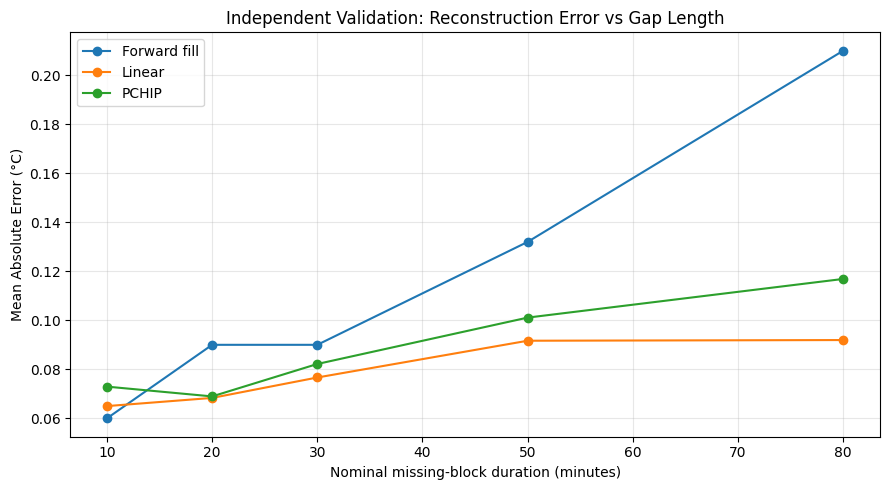

In [ ]:
#plotting the independent calidation results
plt.figure(figsize=(9, 5))

for method, group in validation_summary.groupby("method"):

    plt.plot(
        group["gap_length"] * 10,
        group["mean_MAE"],
        marker="o",
        label=method)

plt.xlabel("Nominal missing-block duration (minutes)")
plt.ylabel("Mean Absolute Error (°C)")
plt.title("Independent Validation: Reconstruction Error vs Gap Length")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#make sure that teh development and evaluation periods do not overlap

developement_times = set(test_series.index)

for i, segment in enumerate(validation_segments, start=1):
    overlap = developement_times.intersection(set(segment.index))

    print(
        f"Validation segment {i}:"
        f"{len(overlap)} timestamps overlap with development"
    )

    assert len(overlap) == 0, (
        "development and validation timestamps overlap"
    )


Validation segment 1:0 timestamps overlap with development
Validation segment 2:0 timestamps overlap with development


In [ ]:
#computational performance and optimisation

from timeit import repeat
from scipy.interpolate import PchipInterpolator

#repeat the 5pt gap for all methods
series = test_series ["temperature"].copy()
gap_length = 5
gap_start = len(series) //2 - gap_length // 2

incomplete = series.copy()
incomplete.iloc[gap_start:gap_start + gap_length] = np.nan

t = (
    series.index - series.index[0]
).total_seconds().to_numpy() / 60

known = incomplete.notna().to_numpy()
hidden = ~known

x_known = t[known]
y_known = incomplete.to_numpy()[known]
x_hidden = t[hidden]

#define the equivalent reconstruction tasks
def benchmark_forward():
    return incomplete.ffill().to_numpy()[hidden]

def benchmark_linear():
    return np.interp(x_hidden, x_known, y_known)


def benchmark_pchip():
    model = PchipInterpolator(
        x_known, y_known, extrapolate=False
    )
    return model(x_hidden)

methods = {
    "Forward fill": benchmark_forward,
    "Linear": benchmark_linear,
    "PCHIP": benchmark_pchip
}

benchmark_results = []

for name, function in methods.items():

    timings = repeat(
        function,
        number=1000,
        repeat=5
    )

    benchmark_results.append({
        "Method": name,
        "Median time (s)": np.median(timings),
        "Best time (s)": min(timings)
    })

benchmark_df = pd.DataFrame(benchmark_results)

# Milliseconds per execution
benchmark_df["Median time (s)"] = (
    benchmark_df["Median time (s)"] / 1000 * 1000
)
benchmark_df["Best time (s)"] = (
    benchmark_df["Best time (s)"] / 1000 * 1000
)

display(benchmark_df.round(6))


,Method,Median time (s),Best time (s)
0,Forward fill,0.049996,0.047235
1,Linear,0.001484,0.001429
2,PCHIP,0.248568,0.230881


# Have a look at the individual method's performance

do they behave correctly?

In [ ]:
#testing linear interpolation
def test_linear_interpolation():
    """Check linear interpolation against a known exact answer."""

    # Known measurements
    times = np.array([0, 10, 30], dtype=float)
    temperatures = np.array([20, 22, 26], dtype=float)

    # Estimate temperature at 20 minutes
    predicted = np.interp(20, times, temperatures)

    # The mathematical answer is exactly 24°C
    expected = 24.0

    assert np.isclose(predicted, expected)
    print("PASS: Linear interpolation")


test_linear_interpolation()

PASS: Linear interpolation


In [ ]:
#test forward fill
def test_forward_fill():
    """Check that missing values use the previous observation."""

    temperatures = pd.Series([20.0, np.nan, np.nan, 26.0])

    predicted = temperatures.ffill()

    expected = np.array([20.0, 20.0, 20.0, 26.0])

    assert np.allclose(predicted.to_numpy(), expected)
    print("PASS: Forward fill")


test_forward_fill()


PASS: Forward fill


In [ ]:
#test the PCHIP method

def test_pchip_interpolation():
    """Check PCHIP on constant data at known nodes."""

    times = np.array([0,10,20,30], dtype=float)
    temperatures = np.array([23.0, 23.0, 23.0,23.0])

    model = PchipInterpolator(
        times, temperatures, extrapolate=False
    )

    # Constant inputs should give constant predictions
    predicted = model(np.array([5, 15, 25]))

    assert np.allclose(predicted, 23.0)

    # PCHIP should reproduce known observations
    assert np.allclose(model(times), temperatures)

    # Unsupported extrapolation should return NaN
    assert np.isnan(model(-5))

    print("PASS: PCHIP interpolation")


test_pchip_interpolation()




PASS: PCHIP interpolation


In [ ]:
#we then verify the error calculations

def test_error_metrics():
    """Verify MAE and RMSE against manually calculated values."""

    actual = np.array([20.0, 22.0, 24.0])
    predicted = np.array([21.0, 21.0, 22.0])

    mae, rmse = calculate_errors(actual, predicted)

    assert np.isclose(mae, 4 / 3)
    assert np.isclose(rmse, np.sqrt(2))

    print("PASS: MAE and RMSE calculations")


test_error_metrics()


PASS: MAE and RMSE calculations


In [ ]:
#we then test the invalid inputs
#the function we used upto this point has protection against mismatched arrays and non-finite temperatures

#the function should reject them

def test_invalid_inputs():
  """check that invalid error metric inputs are rejected"""

  #different sized arrays must raise an error
  try:
      calculate_errors([20,21],[20])
      raise AssertionError("Mismatched arrays were accepted")
  except ValueError:
      pass

  #with this, all the NaN values must raise an error
  try:
        calculate_errors([20, np.nan], [20, 21])
        raise AssertionError("NaN inputs were accepted")
  except ValueError:
        pass

  print("PASS: Invalid input handling")


test_invalid_inputs()

PASS: Invalid input handling


In [ ]:
#now we need to test our full reconstruct gap function
#we can just reply on nump and scipy to prove that our code connects the methods correctly

def test_complete_reconstruction():
    """Check reconstruction against a known linear temperature series."""

    # Create a simple time series with a known trend
    times = pd.date_range(
        "2024-01-01",
        periods=12,
        freq="10min",
        tz="UTC"
    )
    temperatures = pd.Series(
        20.0 + 0.2 * np.arange(12),
        index=times
    )
    # Hide three consecutive interior observations
    result = reconstruct_gap(
        temperatures,
        gap_start=4,
        gap_length=3
    )
    # All three methods should exactly reconstruct
    # a straight-line trend in this example
    for method in ["Forward fill", "Linear", "PCHIP"]:
        row = result[result["method"] == method].iloc[0]

        if method in ["Linear", "PCHIP"]:
            assert np.isclose(row["mae"], 0.0)
            assert np.isclose(row["rmse"], 0.0)
        else:
            assert row["mae"] > 0.0

    print("PASS: Complete reconstruction workflow")

test_complete_reconstruction()

PASS: Complete reconstruction workflow


In [ ]:
#we will runa all 6 tests and generate a test reportS
#this way we dont have to execute each verificaiton test manually

# List of verification tests
tests = [
    test_linear_interpolation,
    test_forward_fill,
    test_pchip_interpolation,
    test_error_metrics,
    test_invalid_inputs,
    test_complete_reconstruction
]
test_results = []

for test in tests:
    try:
        test()
        status = "PASSED"
        details = ""

    except Exception as error:
        status = "FAILED"
        details = str(error)

    test_results.append({
        "Test": test.__name__,
        "Status": status,
        "Details": details
    })

test_report = pd.DataFrame(test_results)

display(test_report)

print(
    "Passed:",
    (test_report["Status"] == "PASSED").sum(),
    "out of",
    len(test_report)
)





PASS: Linear interpolation
PASS: Forward fill
PASS: PCHIP interpolation
PASS: MAE and RMSE calculations
PASS: Invalid input handling
PASS: Complete reconstruction workflow


,Test,Status,Details
0,test_linear_interpolation,PASSED,
1,test_forward_fill,PASSED,
2,test_pchip_interpolation,PASSED,
3,test_error_metrics,PASSED,
4,test_invalid_inputs,PASSED,
5,test_complete_reconstruction,PASSED,


Passed: 6 out of 6


In [ ]:
#now we save the test report to google drive, so we dont have to redo it

results_folder = data_folder.parent /"results"
results_folder.mkdir(parents=True, exist_ok=True)

# Save test results as a CSV
test_report.to_csv(
    results_folder / "verification_test_report.csv",
    index=False
)

print("Test report saved successfully.")


Test report saved successfully.


In [ ]:
#a few more final checks
#do the results exist?
assert not validation_results.empty
assert not independent_results.empty
assert not overall_summary.empty

#is every method present in the results?
expected_methods = {"Forward fill", "Linear", "PCHIP"}
assert set(independent_results["method"]) == expected_methods

#any invalid numerical errors?
assert np.isfinite(
    independent_results[["mae", "rmse"]].to_numpy()
).all()

#any negative errors that should not be present?
assert (
    independent_results[["mae", "rmse"]] >= 0
).all().all()

print("PASS: Experimental result consistency checks")


PASS: Experimental result consistency checks
